In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#import cufflinks as cf
#from plotly.offline import iplot
df = pd.read_csv("/kaggle/input/datasets/sakinofbd/bangladesh-aqi-dataset-20002025/AQI Bangladesh.csv")

print("Shape:", df.shape)

Shape: (1048551, 13)


In [2]:
df.head()

,city_id,city_name,lat,lon,datetime,pm10,pm2_5,carbon_monoxide,carbon_dioxide,nitrogen_dioxide,sulphur_dioxide,ozone,aqi
0,7701354,Azimpur,23.7298,90.3854,2022-08-05T00:00,25.0,16.7,252.0,NaN,18.6,5.2,13.0,50.0
1,7701354,Azimpur,23.7298,90.3854,2022-08-05T01:00,18.5,12.3,249.0,NaN,18.5,5.7,19.0,50.0
2,7701354,Azimpur,23.7298,90.3854,2022-08-05T02:00,16.1,10.9,244.0,NaN,18.4,6.5,27.0,51.0
3,7701354,Azimpur,23.7298,90.3854,2022-08-05T03:00,15.4,10.3,233.0,NaN,17.2,6.9,39.0,51.0
4,7701354,Azimpur,23.7298,90.3854,2022-08-05T04:00,16.8,11.3,217.0,NaN,14.8,6.2,51.0,51.0


In [3]:
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048551 entries, 0 to 1048550
Data columns (total 13 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   city_id           1048551 non-null  int64  
 1   city_name         1048551 non-null  object 
 2   lat               1048551 non-null  float64
 3   lon               1048551 non-null  float64
 4   datetime          1048551 non-null  object 
 5   pm10              1048551 non-null  float64
 6   pm2_5             1048551 non-null  float64
 7   carbon_monoxide   1048551 non-null  float64
 8   carbon_dioxide    274224 non-null   float64
 9   nitrogen_dioxide  1048551 non-null  float64
 10  sulphur_dioxide   1048551 non-null  float64
 11  ozone             1048551 non-null  float64
 12  aqi               1047855 non-null  float64
dtypes: float64(10), int64(1), object(2)
memory usage: 104.0+ MB


city_id                  0
city_name                0
lat                      0
lon                      0
datetime                 0
pm10                     0
pm2_5                    0
carbon_monoxide          0
carbon_dioxide      774327
nitrogen_dioxide         0
sulphur_dioxide          0
ozone                    0
aqi                    696
dtype: int64

Here, The dataset contains missing values in two columns. The "carbon_dioxide" column has 774,327 missing (NaN) entries which represents approximately 74% of the data. So, we will ignore that column. The aqi column has only 696 missing values (0.07%). So, we decided to remove that rows where aqi is (NaN). 

In [4]:

df = df.drop(columns=["city_id", "city_name"])
df = df.drop(columns=["carbon_dioxide"])
df = df.dropna(subset=['aqi'])

print(df['aqi'].isnull().sum())

0


In [5]:
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
Index: 1047855 entries, 0 to 1048550
Data columns (total 10 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   lat               1047855 non-null  float64
 1   lon               1047855 non-null  float64
 2   datetime          1047855 non-null  object 
 3   pm10              1047855 non-null  float64
 4   pm2_5             1047855 non-null  float64
 5   carbon_monoxide   1047855 non-null  float64
 6   nitrogen_dioxide  1047855 non-null  float64
 7   sulphur_dioxide   1047855 non-null  float64
 8   ozone             1047855 non-null  float64
 9   aqi               1047855 non-null  float64
dtypes: float64(9), object(1)
memory usage: 87.9+ MB


lat                 0
lon                 0
datetime            0
pm10                0
pm2_5               0
carbon_monoxide     0
nitrogen_dioxide    0
sulphur_dioxide     0
ozone               0
aqi                 0
dtype: int64

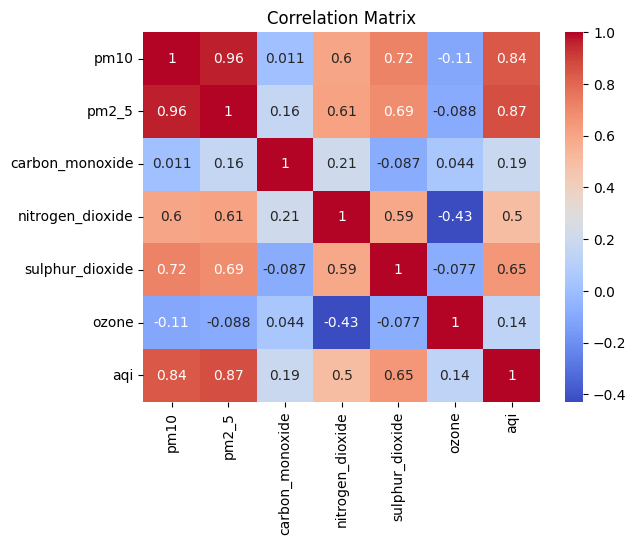

In [6]:
corr = df[["pm10","pm2_5","carbon_monoxide","nitrogen_dioxide","sulphur_dioxide","ozone","aqi"]].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

# Splitting the dataset into test and train


In [7]:

n = len(df)

shuffle = np.random.permutation(n)

split = int(0.7 * n)

train_IDs = shuffle[:split]
test_IDS= shuffle[split:]

AQI_TRAIN = df.iloc[train_IDs]
AQI_TEST = df.iloc[test_IDS]

AQI_TRAIN = AQI_TRAIN.reset_index(drop=True)
AQI_TEST = AQI_TEST.reset_index(drop=True)
print("Train shape:", AQI_TRAIN.shape)
print("Test shape:", AQI_TEST.shape)


Train shape: (733498, 10)
Test shape: (314357, 10)


In [8]:
print(AQI_TRAIN.head())
AQI_TRAIN.duplicated().sum()


        lat       lon          datetime        pm10       pm2_5  \
0  22.48898  90.06273  2023-06-21T22:00   16.800000   10.100000   
1  25.62745  88.63779  2022-12-06T10:00   43.500000   30.300000   
2  23.71040  90.40744  2007-08-02T12:00  100.493365   60.371139   
3  25.03852  91.66958  2024-06-05T19:00   56.300000   36.100000   
4  22.97372  90.22376  2023-01-30T22:00  156.000000  108.500000   

   carbon_monoxide  nitrogen_dioxide  sulphur_dioxide       ozone         aqi  
0       124.000000          1.300000         0.800000   62.000000   41.000000  
1       335.000000          5.500000         4.900000  130.000000  141.000000  
2         1.316231         36.568654         9.769371   51.138263  152.566459  
3       422.000000         10.700000         3.200000   42.000000   84.000000  
4       728.000000         26.400000         4.800000   45.000000  168.000000  


np.int64(0)

In [9]:
print(AQI_TEST.head())
AQI_TEST.duplicated().sum()

        lat       lon          datetime        pm10      pm2_5  \
0  24.02452  88.99234  2023-03-23T01:00  116.900000  81.500000   
1  25.55613  89.67097  2023-07-31T03:00   35.900000  24.400000   
2  22.68768  91.78123  2024-10-07T14:00   43.700000  29.900000   
3  22.19534  92.21946  2025-10-18T14:00   13.600000  13.500000   
4  23.71040  90.40744  2010-03-08T22:00  120.686994  73.017124   

   carbon_monoxide  nitrogen_dioxide  sulphur_dioxide      ozone         aqi  
0       780.000000         43.400000        42.200000  34.000000  154.000000  
1       284.000000          3.300000         4.000000  97.000000   69.000000  
2       450.000000         31.400000         4.600000  30.000000   62.000000  
3       290.000000          9.600000         0.700000  31.000000   34.000000  
4         0.997242         21.959844        32.435363  48.846186  159.229254  


np.int64(0)

# Selecting Features with Strong Positive Correlation


In [10]:
features = ['pm2_5', 'pm10']  
m_train = AQI_TRAIN[features].values   
n_train = AQI_TRAIN['aqi'].values      


m_test  = AQI_TEST[features].values
n_test  = AQI_TEST['aqi'].values

print('m_train shape:', m_train.shape)
print('n_train shape:', n_train.shape)
print('m_test shape:', m_test.shape)
print('n_test shape:', n_test.shape)

m_train shape: (733498, 2)
n_train shape: (733498,)
m_test shape: (314357, 2)
n_test shape: (314357,)


# Adding the bias column


In [11]:



ones_train = np.ones((m_train.shape[0], 1))
ones_test  = np.ones((m_test.shape[0], 1))


A_train = np.hstack([ones_train, m_train])
A_test  = np.hstack([ones_test, m_test])


print('A_train shape:', A_train.shape)   
print('A_test shape:', A_test.shape)

print('First row of A_train:', A_train[0])

A_train shape: (733498, 3)
A_test shape: (314357, 3)
First row of A_train: [ 1.  10.1 16.8]


# Normal Equation


In [12]:
AT      = A_train.T                         
ATA     = AT @ A_train                       
ATA_inv = np.linalg.inv(ATA)                
ATy     = AT @ n_train                      

beta = ATA_inv @ ATy                       

print('Intercept (beta_0):', round(beta[0], 2))
print('Coefficient for pm2_5:', round(beta[1], 2))
print('Coefficient for pm10:', round(beta[2], 2))

Intercept (beta_0): 59.53
Coefficient for pm2_5: 1.08
Coefficient for pm10: 0.01


# Making prediction on trained data

In [13]:
n_train_predictions = A_train @ beta

for i in range(5):
    print(f'Actual: {n_train[i]:.0f}   Predicted: {n_train_predictions[i]:.0f}')

Actual: 41   Predicted: 71
Actual: 141   Predicted: 93
Actual: 153   Predicted: 126
Actual: 84   Predicted: 99
Actual: 168   Predicted: 178


# Calculatting MSE

In [14]:
# Predictions
n_test_predictions = A_test @ beta

# Errors
errors = n_test - n_test_predictions

# MSE and RMSE
squared = errors ** 2
mse = squared.mean()
rmse = mse ** 0.5

# MAE
mae = abs(errors).mean()

# R² 
ss_res = (errors ** 2).sum()
ss_tot = ((n_test - n_test.mean()) ** 2).sum()
r2 = 1 - (ss_res / ss_tot)

# Print results
print('Test MSE: ', round(mse, 2))
print('Test RMSE:', round(rmse, 2))
print('Test MAE: ', round(mae, 2))
print('Test R2:  ', round(r2, 4))

Test MSE:  666.67
Test RMSE: 25.82
Test MAE:  21.08
Test R2:   0.7596


# Visualise prediction vs actual

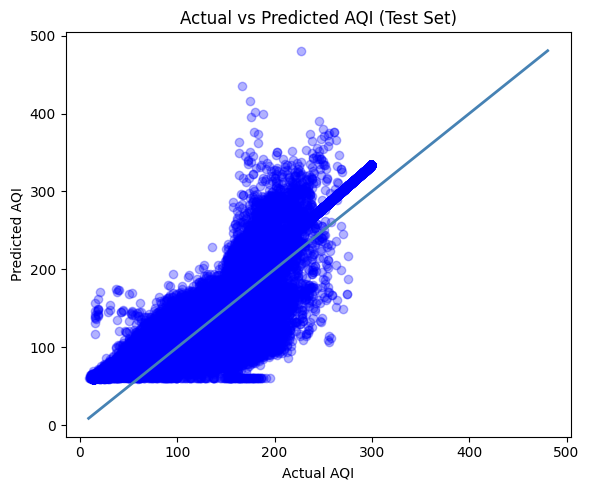

In [15]:
plt.figure(figsize=(6, 5))
plt.scatter(n_test, n_test_predictions, alpha=0.3, color='blue')


min_val = min(n_test.min(), n_test_predictions.min())
max_val = max(n_test.max(), n_test_predictions.max())
plt.plot([min_val, max_val], [min_val, max_val], color='steelblue', linewidth=2)

plt.xlabel('Actual AQI')
plt.ylabel('Predicted AQI')
plt.title('Actual vs Predicted AQI (Test Set)')
plt.tight_layout()
plt.show()

In [16]:
X_train = AQI_TRAIN[['pm2_5', 'pm10']].values
y_train = AQI_TRAIN['aqi'].values

X_test  = AQI_TEST[['pm2_5', 'pm10']].values
y_test  = AQI_TEST['aqi'].values

In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_norm = scaler.fit_transform(X_train)
X_test_norm = scaler.transform(X_test)

# add bias column
A_train_norm = np.hstack([np.ones((X_train_norm.shape[0], 1)), X_train_norm])
A_test_norm  = np.hstack([np.ones((X_test_norm.shape[0], 1)), X_test_norm])

print(A_train_norm.shape)

(733498, 3)


In [18]:
beta_gd = np.zeros(A_train_norm.shape[1])  # [b0, b1, b2]

alpha = 0.01        # learning rate (you can tune 0.001–0.05)
iterations = 20000  # more steps for stability
n = len(y_train)

mse_history = []

In [19]:
for i in range(iterations):

    # predictions
    y_hat = A_train_norm @ beta_gd

    # error
    error = y_hat - y_train

    # gradient
    gradient = (A_train_norm.T @ error) / n

    # update weights
    beta_gd = beta_gd - alpha * gradient

    # track loss
    mse_history.append((error ** 2).mean())

    # optional print
    if i % 200 == 0:
        print(f"Iteration {i}, MSE: {mse_history[-1]:.2f}")

Iteration 0, MSE: 15991.07
Iteration 200, MSE: 938.71
Iteration 400, MSE: 700.26
Iteration 600, MSE: 692.11
Iteration 800, MSE: 688.63
Iteration 1000, MSE: 685.70
Iteration 1200, MSE: 683.18
Iteration 1400, MSE: 681.02
Iteration 1600, MSE: 679.17
Iteration 1800, MSE: 677.57
Iteration 2000, MSE: 676.20
Iteration 2200, MSE: 675.03
Iteration 2400, MSE: 674.01
Iteration 2600, MSE: 673.15
Iteration 2800, MSE: 672.40
Iteration 3000, MSE: 671.76
Iteration 3200, MSE: 671.21
Iteration 3400, MSE: 670.73
Iteration 3600, MSE: 670.33
Iteration 3800, MSE: 669.98
Iteration 4000, MSE: 669.68
Iteration 4200, MSE: 669.42
Iteration 4400, MSE: 669.20
Iteration 4600, MSE: 669.00
Iteration 4800, MSE: 668.84
Iteration 5000, MSE: 668.70
Iteration 5200, MSE: 668.58
Iteration 5400, MSE: 668.48
Iteration 5600, MSE: 668.39
Iteration 5800, MSE: 668.31
Iteration 6000, MSE: 668.24
Iteration 6200, MSE: 668.19
Iteration 6400, MSE: 668.14
Iteration 6600, MSE: 668.10
Iteration 6800, MSE: 668.06
Iteration 7000, MSE: 668.

In [20]:
print("Gradient Descent Parameters:")
print("Intercept:", beta_gd[0])
print("pm2_5 coef:", beta_gd[1])
print("pm10  coef:", beta_gd[2])

Gradient Descent Parameters:
Intercept: 114.98989609571122
pm2_5 coef: 45.33523393997054
pm10  coef: 0.5154239605867444


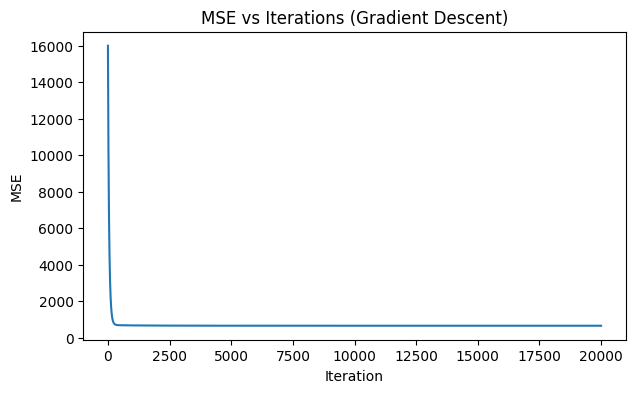

In [21]:
plt.figure(figsize=(7,4))
plt.plot(mse_history)
plt.title("MSE vs Iterations (Gradient Descent)")
plt.xlabel("Iteration")
plt.ylabel("MSE")
plt.show()

In [22]:
y_pred_gd = A_test_norm @ beta_gd

errors = y_test - y_pred_gd

mse  = (errors ** 2).mean()
rmse = mse ** 0.5
mae  = np.abs(errors).mean()

ss_res = (errors ** 2).sum()
ss_tot = ((y_test - y_test.mean()) ** 2).sum()
r2 = 1 - ss_res / ss_tot

print("GD Test MSE :", round(mse, 2))
print("GD Test RMSE:", round(rmse, 2))
print("GD Test MAE :", round(mae, 2))
print("GD Test R2  :", round(r2, 4))

GD Test MSE : 666.67
GD Test RMSE: 25.82
GD Test MAE : 21.08
GD Test R2  : 0.7596
